# Task 5 — Seleção do modelo final e avaliação no teste

Esta task fecha o projeto: escolhe o modelo final **apenas com dados de desenvolvimento**, congela todas as decisões (pré-processamento, variáveis, hiperparâmetros e limiar), avalia **uma única vez** o período de teste final e analisa onde e porquê o modelo acerta ou falha.

Regras de disciplina seguidas neste notebook:

- Os hiperparâmetros vêm da Task 4 e não são otimizados de novo.
- O limiar do modelo e o limiar da baseline são escolhidos com as mesmas sessões de desenvolvimento (previsões out-of-fold dos 4 folds temporais), pelo mesmo critério (F2 máximo).
- O modelo é treinado uma vez com todo o desenvolvimento e prevê o teste uma vez. As análises por período, por grupo e de erros são **descritivas**: reutilizam essas previsões e não alteram nenhuma decisão.

## 5.0 Preparação

Carregamento dos dados, preditores elegíveis e folds temporais do protocolo da Task 2 (os mesmos da Task 4).

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import (
    average_precision_score, balanced_accuracy_score, brier_score_loss, confusion_matrix,
    f1_score, fbeta_score, matthews_corrcoef, precision_recall_curve, precision_score,
    recall_score, roc_auc_score,
)

warnings.filterwarnings("ignore", message="A worker stopped")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

DATA_PATH = Path("Charging_Data_educational.csv")
PROTOCOL_PATH = Path("validation_protocol_task2.json")
PREDICTORS_PATH = Path("predictors_task2.json")

for path in [DATA_PATH, PROTOCOL_PATH, PREDICTORS_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Não foi encontrado {path}. Coloca este ficheiro na mesma pasta que task5.ipynb.")

protocol = json.loads(PROTOCOL_PATH.read_text(encoding="utf-8"))
eligible_predictors = json.loads(PREDICTORS_PATH.read_text(encoding="utf-8"))["eligible_predictors"]

df = pd.read_csv(DATA_PATH)
df.columns = (
    df.columns.astype(str).str.strip().str.lower()
    .str.replace(r"[^a-zA-Z0-9]+", "_", regex=True).str.strip("_")
)

start_dt = pd.to_datetime(df["start_time"], errors="coerce")
end_dt = pd.to_datetime(df["end_time"], errors="coerce")

NORMAL_END_CAUSES = {"Charging ends normally", "User stops charging"}
y = (~df["end_cause"].isin(NORMAL_END_CAUSES)).astype(int)

CATEGORICAL = ["charging_post_id", "location_information", "district_name", "tariff_period"]

def build_features(frame):
    X_local = frame[eligible_predictors].copy()
    hour = start_dt.dt.hour + start_dt.dt.minute / 60
    X_local["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    X_local["hour_cos"] = np.cos(2 * np.pi * hour / 24)
    X_local["weekday_sin"] = np.sin(2 * np.pi * start_dt.dt.day_of_week / 7)
    X_local["weekday_cos"] = np.cos(2 * np.pi * start_dt.dt.day_of_week / 7)
    X_local = X_local.drop(columns="start_time")
    X_local[CATEGORICAL] = X_local[CATEGORICAL].astype(str)
    numeric = [col for col in X_local.columns if col not in CATEGORICAL]
    X_local[numeric] = X_local[numeric].astype(float)
    return X_local

X = build_features(df)
numeric_cols = [col for col in X.columns if col not in CATEGORICAL]

TEST_START = pd.Timestamp(protocol["test_start"])
N_FOLDS = int(protocol["n_folds"])
FOLD_MONTHS = int(protocol["fold_months"])
val_starts = [TEST_START - pd.DateOffset(months=FOLD_MONTHS * (N_FOLDS - k)) for k in range(N_FOLDS)]
val_ends = val_starts[1:] + [TEST_START]

folds = []
for v_start, v_end in zip(val_starts, val_ends):
    val_idx = np.flatnonzero(((start_dt >= v_start) & (start_dt < v_end)).to_numpy())
    train_idx = np.flatnonzero(((start_dt < v_start) & (end_dt < v_start)).to_numpy())
    folds.append((train_idx, val_idx))

for k, (train_idx, val_idx) in enumerate(folds):
    expected = protocol["folds"][k]
    assert (len(train_idx), len(val_idx)) == (expected["n_treino"], expected["n_validacao"]), f"Fold {k + 1} difere do protocolo."

oof_idx = np.concatenate([val_idx for _, val_idx in folds])
base_all = X["post_previous_abnormal_rate_30d"].fillna(0.0).to_numpy()

print(f"Sessões: {len(df):,} | preditores: {X.shape[1]} | teste final a partir de {TEST_START.date()}")
print(f"Folds (treino, validação): {[(len(tr), len(va)) for tr, va in folds]}")

Sessões: 441,077 | preditores: 40 | teste final a partir de 2021-08-01
Folds (treino, validação): [(79695, 66045), (145748, 57027), (202793, 42189), (244950, 64938)]


In [2]:
RANDOM_STATE = 42
TREE_MIN_SAMPLES_LEAF = 200

def numeric_scaled():
    return Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])

def make_logistic(C=1.0):
    prep = ColumnTransformer([
        ("num", numeric_scaled(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), CATEGORICAL),
    ])
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=C, max_iter=1000))])

def ensemble_tree_preprocessor():
    return ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), numeric_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CATEGORICAL),
    ])

def make_random_forest(n_estimators=100, max_depth=None, min_samples_leaf=TREE_MIN_SAMPLES_LEAF, max_features="sqrt"):
    clf = RandomForestClassifier(
        n_estimators=n_estimators, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
        max_features=max_features, random_state=RANDOM_STATE, n_jobs=-1,
    )
    return Pipeline([("prep", ensemble_tree_preprocessor()), ("clf", clf)])

def make_boosting(learning_rate=0.1, max_iter=100, max_leaf_nodes=31, l2_regularization=0.0):
    clf = HistGradientBoostingClassifier(
        learning_rate=learning_rate, max_iter=max_iter, max_leaf_nodes=max_leaf_nodes,
        l2_regularization=l2_regularization, random_state=RANDOM_STATE,
    )
    return Pipeline([("prep", ensemble_tree_preprocessor()), ("clf", clf)])

def build_candidate(model_name, params):
    if model_name == "Logistic Regression":
        return make_logistic(**params)
    if model_name == "Random Forest":
        return make_random_forest(**params)
    if model_name == "HistGradientBoosting":
        return make_boosting(**params)
    raise ValueError(f"Modelo desconhecido: {model_name}")

# Melhores configurações da Task 4 (secção 4.5). Não são otimizadas de novo aqui.
SELECTED_CONFIGS = {
    "Logistic Regression": {"C": 0.1},
    "Random Forest": {"n_estimators": 100, "max_depth": 16, "min_samples_leaf": 100, "max_features": "sqrt"},
    "HistGradientBoosting": {"learning_rate": 0.05, "max_iter": 100, "max_leaf_nodes": 31, "l2_regularization": 0.0},
}
print("Modelos candidatos:", list(SELECTED_CONFIGS))

Modelos candidatos: ['Logistic Regression', 'Random Forest', 'HistGradientBoosting']


## 5.1 Seleção do modelo final (apenas desenvolvimento)

Os três candidatos da Task 4, com as configurações otimizadas, são reavaliados nos mesmos 4 folds temporais, juntamente com a **baseline** escolhida para esta task: a taxa de anomalias do posto nos 30 dias anteriores (`post_previous_abnormal_rate_30d`). É uma regra sem aprendizagem, disponível no início da sessão, que qualquer operador poderia aplicar; mostra quanto a aprendizagem automática acrescenta além de "olhar para o histórico recente do posto". A prevalência é apenas a referência de um classificador sem poder discriminativo.

Critérios: desempenho preditivo (PR-AUC média), estabilidade temporal (desvio-padrão e pior fold), custo computacional (tempo de treino), calibração (Brier) e interpretabilidade.

,AP média,AP std,Pior fold AP,Folds acima da baseline,Brier médio,Tempo médio/fold (s),Interpretabilidade
Modelo,,,,,,,
Logistic Regression,0.5830,0.0596,0.5010,4/4,0.1045,1.2551,Alta (coeficientes e odds ratios)
Random Forest,0.6161,0.0571,0.5373,4/4,0.1006,3.9540,Média (importância por permutação)
HistGradientBoosting,0.6210,0.0560,0.5444,4/4,0.0997,2.0976,Média (importância por permutação e PDP)
Baseline: taxa do posto 30d,0.4324,0.0488,0.3617,-,NaN,0.0000,Total (regra direta)


PR-AUC por fold:


,Logistic Regression,Random Forest,HistGradientBoosting,Baseline: taxa do posto 30d,Prevalência
Fold 1,0.6172,0.6458,0.6512,0.4604,0.1868
Fold 2,0.5782,0.6132,0.6162,0.4387,0.1679
Fold 3,0.5010,0.5373,0.5444,0.3617,0.1532
Fold 4,0.6353,0.6680,0.6721,0.4688,0.1943


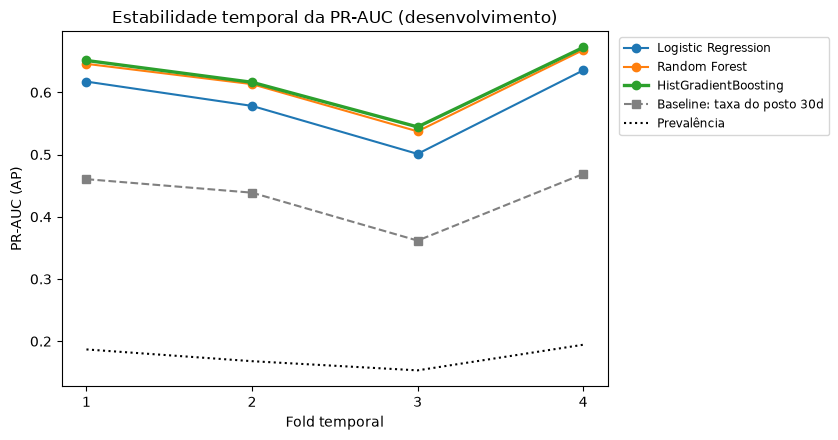

Modelo selecionado: HistGradientBoosting {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31, 'l2_regularization': 0.0}


In [3]:
oof_probs = {}
select_rows = []
fold_ap = {}

y_oof = y.to_numpy()[oof_idx]

for name, params in SELECTED_CONFIGS.items():
    aps, briers, seconds, probs = [], [], [], []
    for train_idx, val_idx in folds:
        model = build_candidate(name, params)
        started = time.perf_counter()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        seconds.append(time.perf_counter() - started)
        prob = model.predict_proba(X.iloc[val_idx])[:, 1]
        probs.append(prob)
        aps.append(average_precision_score(y.iloc[val_idx], prob))
        briers.append(brier_score_loss(y.iloc[val_idx], prob))
    oof_probs[name] = np.concatenate(probs)
    fold_ap[name] = aps
    select_rows.append({"Modelo": name, "aps": aps, "Brier médio": np.mean(briers), "Tempo médio/fold (s)": np.mean(seconds)})

fold_ap["Baseline: taxa do posto 30d"] = [
    average_precision_score(y.iloc[val_idx], base_all[val_idx]) for _, val_idx in folds
]
fold_prevalence = [y.iloc[val_idx].mean() for _, val_idx in folds]
baseline_aps = np.array(fold_ap["Baseline: taxa do posto 30d"])

INTERPRETABILITY = {
    "Logistic Regression": "Alta (coeficientes e odds ratios)",
    "Random Forest": "Média (importância por permutação)",
    "HistGradientBoosting": "Média (importância por permutação e PDP)",
}

rows = []
for row in select_rows:
    aps = np.array(row["aps"])
    rows.append({
        "Modelo": row["Modelo"],
        "AP média": aps.mean(),
        "AP std": aps.std(ddof=1),
        "Pior fold AP": aps.min(),
        "Folds acima da baseline": f"{int((aps > baseline_aps).sum())}/{len(aps)}",
        "Brier médio": row["Brier médio"],
        "Tempo médio/fold (s)": row["Tempo médio/fold (s)"],
        "Interpretabilidade": INTERPRETABILITY[row["Modelo"]],
    })
rows.append({
    "Modelo": "Baseline: taxa do posto 30d",
    "AP média": baseline_aps.mean(), "AP std": baseline_aps.std(ddof=1), "Pior fold AP": baseline_aps.min(),
    "Folds acima da baseline": "-", "Brier médio": np.nan, "Tempo médio/fold (s)": 0.0,
    "Interpretabilidade": "Total (regra direta)",
})
selection = pd.DataFrame(rows).set_index("Modelo")
display(selection.round(4))

per_fold = pd.DataFrame(fold_ap, index=[f"Fold {k + 1}" for k in range(len(folds))])
per_fold["Prevalência"] = fold_prevalence
print("PR-AUC por fold:")
display(per_fold.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
x_axis = np.arange(1, len(folds) + 1)
for name in SELECTED_CONFIGS:
    ax.plot(x_axis, fold_ap[name], marker="o", lw=2.4 if name == "HistGradientBoosting" else 1.5, label=name)
ax.plot(x_axis, baseline_aps, marker="s", ls="--", color="grey", label="Baseline: taxa do posto 30d")
ax.plot(x_axis, fold_prevalence, ls=":", color="black", label="Prevalência")
ax.set(xlabel="Fold temporal", ylabel="PR-AUC (AP)", title="Estabilidade temporal da PR-AUC (desenvolvimento)", xticks=x_axis)
ax.legend(fontsize=8.5, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

models_only = selection.drop(index="Baseline: taxa do posto 30d")
FINAL_MODEL_NAME = models_only["AP média"].idxmax()
FINAL_PARAMS = SELECTED_CONFIGS[FINAL_MODEL_NAME]
print(f"Modelo selecionado: {FINAL_MODEL_NAME} {FINAL_PARAMS}")
assert FINAL_MODEL_NAME == "HistGradientBoosting", "A seleção deixou de coincidir com a Task 4."

**Decisão (apenas com dados de desenvolvimento).** Escolhe-se o `HistGradientBoosting`.

| Critério | Evidência | Leitura |
|---|---|---|
| Desempenho | PR-AUC média 0,621 (RF 0,616; LR 0,583; baseline 0,432) | Os três modelos superam a baseline em 4 de 4 folds; o HGB é o melhor em todos os folds. |
| Estabilidade temporal | Pior fold 0,544 (RF 0,537; LR 0,501) | O HGB tem o melhor pior caso. O desvio-padrão entre folds (0,056) é muito maior do que a diferença HGB-RF (0,005), por isso a vantagem sobre a RF é pequena e não está suportada estatisticamente. |
| Calibração | Brier 0,0997 (RF 0,1006; LR 0,1045) | As probabilidades são razoavelmente calibradas, o que é necessário para escolher um limiar por custos. |
| Custo computacional | cerca de 2 s por fold (RF 4 s; LR 1 s) | Os três treinam em segundos; o custo não é decisivo e permite retreinar com frequência, útil porque a prevalência varia no tempo. |
| Interpretabilidade | LR: coeficientes diretos; HGB: importância por permutação e PDP | Perde-se interpretabilidade direta (a LR custa -0,038 de PR-AUC). A compensação está na secção 5.6. |
| Implicação operacional | Usa só informação disponível no início da sessão | Pode gerar um alerta antes da sessão terminar, sem fuga de informação. |

**Baseline.** A taxa de anomalias do posto nos últimos 30 dias é o termo de comparação adequado: é o que um operador faria sem modelo, usa apenas informação do início da sessão e já é muito informativa (PR-AUC 0,432 contra uma prevalência de 0,176). O modelo só se justifica se a superar com folga.

## 5.2 Congelamento das decisões e avaliação única no teste final

O limiar do modelo é o que maximiza o **F2** nas previsões out-of-fold dos folds de desenvolvimento (o F2 pesa mais o recall, porque um falso negativo é o erro mais grave). Para a baseline usa-se o **mesmo critério, nas mesmas sessões**. Depois, o modelo é reajustado com todo o desenvolvimento (com purga por `end_time`) e prevê o teste uma única vez.

In [4]:
def f2_table(score, y_true, grid):
    rows = []
    for threshold in grid:
        pred = (score >= threshold).astype(int)
        rows.append({
            "Limiar": float(threshold),
            "Precisão": precision_score(y_true, pred, zero_division=0),
            "Recall": recall_score(y_true, pred, zero_division=0),
            "F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
            "Alertas por 1000": 1000 * pred.mean(),
        })
    table = pd.DataFrame(rows)
    best = table["F2"].max()
    # Em caso de empate escolhe-se o maior limiar (menos alertas).
    chosen = float(table.loc[table["F2"] >= best - 1e-12, "Limiar"].max())
    return table, chosen

model_grid = np.unique(np.r_[np.arange(0.05, 0.951, 0.01), 0.2, 0.5])
model_table, THRESHOLD_STAR = f2_table(oof_probs[FINAL_MODEL_NAME], y_oof, model_grid)

base_oof = base_all[oof_idx]
base_grid = np.unique(np.r_[np.arange(0.01, 0.951, 0.01), 0.2, 0.5])
base_table, BASE_THRESHOLD = f2_table(base_oof, y_oof, base_grid)

print(f"Limiar do modelo (F2 máximo no desenvolvimento): {THRESHOLD_STAR:.2f}")
print(f"Limiar da baseline (F2 máximo no desenvolvimento): {BASE_THRESHOLD:.2f}")
assert abs(THRESHOLD_STAR - 0.12) < 1e-9, "O limiar deixou de coincidir com a Task 4."

compare_dev = pd.DataFrame({
    "Modelo (limiar escolhido)": model_table.set_index("Limiar").loc[THRESHOLD_STAR],
    "Baseline (limiar escolhido)": base_table.set_index("Limiar").loc[BASE_THRESHOLD],
}).T
display(compare_dev.round(4))

Limiar do modelo (F2 máximo no desenvolvimento): 0.12
Limiar da baseline (F2 máximo no desenvolvimento): 0.11


,Precisão,Recall,F2,Alertas por 1000
Modelo (limiar escolhido),0.3390,0.8292,0.6432,435.6057
Baseline (limiar escolhido),0.2713,0.8382,0.5911,550.2717


O limiar do modelo (0,12) e o da baseline (0,11) foram escolhidos pelo mesmo critério (F2 máximo) e nas mesmas sessões de desenvolvimento. Com recall semelhante (0,829 contra 0,838), o modelo precisa de menos alertas (436 contra 550 por 1000 sessões) e tem maior precisão (0,339 contra 0,271).

In [5]:
# Decisões congeladas. A partir daqui nada é reajustado com o teste.
FROZEN = {"model": FINAL_MODEL_NAME, "params": dict(FINAL_PARAMS), "threshold": THRESHOLD_STAR, "baseline_threshold": BASE_THRESHOLD}
print(FROZEN)

final_train_idx = np.flatnonzero(((start_dt < TEST_START) & (end_dt < TEST_START)).to_numpy())
final_test_idx = np.flatnonzero((start_dt >= TEST_START).to_numpy())

final_model = build_candidate(FROZEN["model"], FROZEN["params"])
final_model.fit(X.iloc[final_train_idx], y.iloc[final_train_idx])
prob_test = final_model.predict_proba(X.iloc[final_test_idx])[:, 1]   # única previsão do teste

test = X.iloc[final_test_idx].copy()
test["y"] = y.iloc[final_test_idx].to_numpy()
test["end_cause"] = df["end_cause"].iloc[final_test_idx].to_numpy()
test["start"] = start_dt.iloc[final_test_idx].to_numpy()
test["month"] = start_dt.iloc[final_test_idx].dt.strftime("%Y-%m").to_numpy()
test["hour"] = start_dt.iloc[final_test_idx].dt.hour.to_numpy()
test["weekday"] = start_dt.iloc[final_test_idx].dt.day_name().to_numpy()
test["location"] = df["location_information"].iloc[final_test_idx].str.strip().to_numpy()
test["prob"] = prob_test
test["base"] = base_all[final_test_idx]
test["alert_model"] = (test["prob"] >= FROZEN["threshold"]).astype(int)
test["alert_base"] = (test["base"] >= FROZEN["baseline_threshold"]).astype(int)
test["outcome"] = np.select(
    [(test["y"] == 1) & (test["alert_model"] == 1), (test["y"] == 0) & (test["alert_model"] == 1), (test["y"] == 1)],
    ["TP", "FP", "FN"], default="TN",
)
print(f"Treino final: {len(final_train_idx):,} sessões | teste final: {len(final_test_idx):,} sessões | prevalência no teste: {test['y'].mean():.4f}")

{'model': 'HistGradientBoosting', 'params': {'learning_rate': 0.05, 'max_iter': 100, 'max_leaf_nodes': 31, 'l2_regularization': 0.0}, 'threshold': 0.12000000000000002, 'baseline_threshold': 0.11}


Treino final: 309,892 sessões | teste final: 131,147 sessões | prevalência no teste: 0.1927


### Comparação com a baseline no teste final

,Baseline (taxa do posto 30d >= 0.11),Modelo final HGB (limiar 0.12),"Modelo HGB (limiar 0,50, referência da Task 4)",Baseline a igual taxa de alertas do modelo (descritivo)
PR-AUC (AP),0.3889,0.5934,0.5934,0.3889
Precisão,0.2604,0.3185,0.7168,0.2933
Recall,0.8793,0.8427,0.3472,0.7760
F1,0.4018,0.4623,0.4678,0.4257
F2,0.5960,0.6340,0.3871,0.5838
Balanced accuracy,0.6416,0.7062,0.6572,0.6648
MCC,0.2343,0.3253,0.4263,0.2601
Taxa de alertas,0.6507,0.5099,0.0933,0.5099
Alertas corretos / 1000 (TP),169.4358,162.3903,66.9020,149.5345
Falsos alertas / 1000 (FP),481.2386,347.4879,26.4360,360.3514


Prevalência no teste (PR-AUC sem poder discriminativo): 0.1927 | balanced accuracy de referência: 0,5 | MCC de referência: 0
ROC-AUC no teste: modelo = 0.8129 | baseline = 0.7345 | Brier do modelo = 0.1146


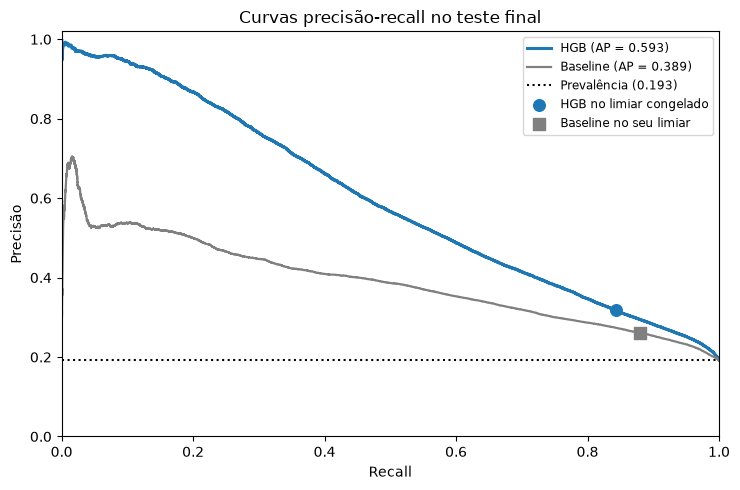

In [6]:
def full_metrics(y_true, score, alert):
    y_true = np.asarray(y_true)
    alert = np.asarray(alert).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, alert, labels=[0, 1]).ravel()
    n = len(y_true)
    return {
        "PR-AUC (AP)": average_precision_score(y_true, score),
        "Precisão": precision_score(y_true, alert, zero_division=0),
        "Recall": recall_score(y_true, alert, zero_division=0),
        "F1": f1_score(y_true, alert, zero_division=0),
        "F2": fbeta_score(y_true, alert, beta=2, zero_division=0),
        "Balanced accuracy": balanced_accuracy_score(y_true, alert),
        "MCC": matthews_corrcoef(y_true, alert),
        "Taxa de alertas": alert.mean(),
        "Alertas corretos / 1000 (TP)": 1000 * tp / n,
        "Falsos alertas / 1000 (FP)": 1000 * fp / n,
        "Anomalias perdidas / 1000 (FN)": 1000 * fn / n,
    }

y_t = test["y"].to_numpy()
alert_050 = (test["prob"] >= 0.50).astype(int)

# Comparação descritiva a igual carga de alertas: não é uma decisão e não altera o limiar congelado.
threshold_equal = np.quantile(test["base"], 1 - test["alert_model"].mean())
alert_base_equal = (test["base"] >= threshold_equal).astype(int)

comparison = pd.DataFrame({
    f"Baseline (taxa do posto 30d >= {FROZEN['baseline_threshold']:.2f})": full_metrics(y_t, test["base"], test["alert_base"]),
    f"Modelo final HGB (limiar {FROZEN['threshold']:.2f})": full_metrics(y_t, test["prob"], test["alert_model"]),
    "Modelo HGB (limiar 0,50, referência da Task 4)": full_metrics(y_t, test["prob"], alert_050),
    "Baseline a igual taxa de alertas do modelo (descritivo)": full_metrics(y_t, test["base"], alert_base_equal),
})
display(comparison.round(4))
print(f"Prevalência no teste (PR-AUC sem poder discriminativo): {y_t.mean():.4f} | balanced accuracy de referência: 0,5 | MCC de referência: 0")
print("ROC-AUC no teste: modelo =", round(roc_auc_score(y_t, test["prob"]), 4), "| baseline =", round(roc_auc_score(y_t, test["base"]), 4),
      "| Brier do modelo =", round(brier_score_loss(y_t, test["prob"]), 4))

prec_m, rec_m, _ = precision_recall_curve(y_t, test["prob"])
prec_b, rec_b, _ = precision_recall_curve(y_t, test["base"])
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(rec_m, prec_m, lw=2.2, label=f"HGB (AP = {average_precision_score(y_t, test['prob']):.3f})")
ax.plot(rec_b, prec_b, lw=1.6, color="grey", label=f"Baseline (AP = {average_precision_score(y_t, test['base']):.3f})")
ax.axhline(y_t.mean(), ls=":", color="black", label=f"Prevalência ({y_t.mean():.3f})")
m_model = full_metrics(y_t, test["prob"], test["alert_model"])
m_base = full_metrics(y_t, test["base"], test["alert_base"])
ax.scatter([m_model["Recall"]], [m_model["Precisão"]], s=70, zorder=5, color="C0", label="HGB no limiar congelado")
ax.scatter([m_base["Recall"]], [m_base["Precisão"]], s=70, zorder=5, color="grey", marker="s", label="Baseline no seu limiar")
ax.set(xlabel="Recall", ylabel="Precisão", title="Curvas precisão-recall no teste final", xlim=(0, 1), ylim=(0, 1.02))
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

**Leitura (teste final, 131 147 sessões, prevalência 0,193).**

- **Ordenação:** PR-AUC 0,593 contra 0,389 (+0,20) e ROC-AUC 0,813 contra 0,735. A diferença é grande e independente do limiar.
- **No limiar congelado,** o modelo tem precisão 0,319 contra 0,260 e recall 0,843 contra 0,879. A baseline deteta mais anomalias porque alerta 65 % das sessões (modelo: 51 %). As métricas que combinam os dois tipos de erro favorecem o modelo: F1 0,462 contra 0,402, balanced accuracy 0,706 contra 0,642, MCC 0,325 contra 0,234.
- **A igual taxa de alertas (51 %)** o modelo deteta 84,3 % das anomalias contra 77,6 %, perdendo 30 em vez de 43 por 1000 sessões. É a comparação mais justa: o ganho é real, mas moderado.
- **O limiar é uma decisão de custos.** O limiar 0,50 tem o MCC mais alto (0,426) e a melhor precisão (0,717), mas só deteta 35 % das anomalias; o MCC, a F1 e a precisão preferem-no, o recall, a F2 e a balanced accuracy preferem 0,12. Qual é melhor depende do custo relativo de perder uma anomalia e de um falso alerta (secção 5.7).
- O MCC absoluto de 0,33 mostra que o recall elevado é comprado com muitos falsos alertas (347 por 1000 sessões).

O teste foi usado uma única vez para obter as previsões. A coluna "igual taxa de alertas" e todas as análises seguintes são descritivas, feitas sobre as mesmas previsões, e não alteraram o modelo, o limiar nem as variáveis.

## 5.3 Desempenho por período no teste final

O teste cobre cinco meses (agosto a dezembro de 2021). A taxa de anomalias não é estacionária (Task 1), por isso a PR-AUC de cada mês só se lê face à prevalência desse mês e à baseline. O limiar é o congelado: nada é recalibrado por mês.

,Sessões,Prevalência,AP modelo,AP baseline,Precisão,Recall,Recall baseline,Alertas/1000,FP/1000,FN/1000,% dos FN totais,MCC
month,,,,,,,,,,,,
2021-08,23692,0.208,0.655,0.471,0.357,0.862,0.879,501.097,322.218,28.744,0.171,0.369
2021-09,27374,0.229,0.676,0.452,0.361,0.882,0.914,559.399,357.493,26.923,0.185,0.354
2021-10,27794,0.186,0.549,0.324,0.289,0.840,0.900,541.628,385.335,29.719,0.208,0.286
2021-11,25669,0.165,0.480,0.304,0.281,0.799,0.843,469.282,337.411,33.153,0.214,0.294
2021-12,26618,0.176,0.549,0.370,0.302,0.812,0.844,472.763,329.890,33.023,0.221,0.314


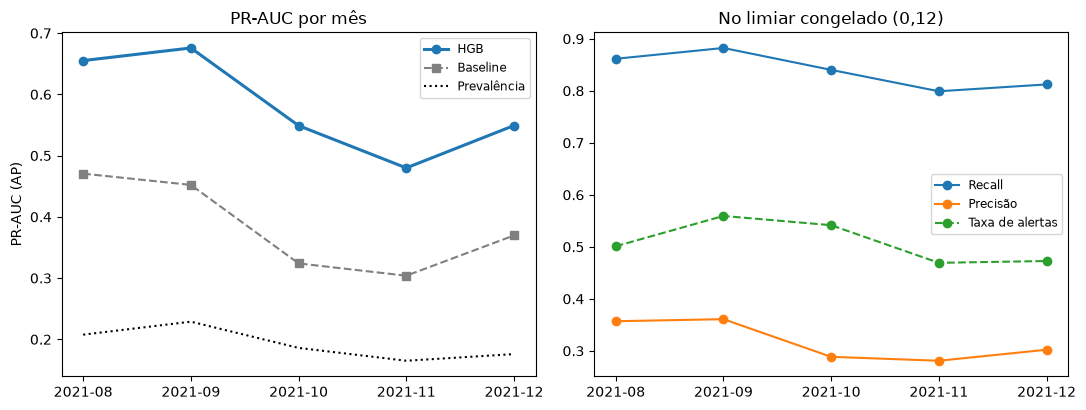

In [7]:
def group_summary(frame, by):
    rows = []
    n_fn_total = (frame["outcome"] == "FN").sum()
    for key, g in frame.groupby(by, observed=True):
        m = full_metrics(g["y"], g["prob"], g["alert_model"])
        b = full_metrics(g["y"], g["base"], g["alert_base"])
        rows.append({
            by: key,
            "Sessões": len(g),
            "Prevalência": g["y"].mean(),
            "AP modelo": m["PR-AUC (AP)"],
            "AP baseline": b["PR-AUC (AP)"],
            "Precisão": m["Precisão"],
            "Recall": m["Recall"],
            "Recall baseline": b["Recall"],
            "Alertas/1000": 1000 * m["Taxa de alertas"],
            "FP/1000": m["Falsos alertas / 1000 (FP)"],
            "FN/1000": m["Anomalias perdidas / 1000 (FN)"],
            "% dos FN totais": (g["outcome"] == "FN").sum() / n_fn_total,
            "MCC": m["MCC"],
        })
    return pd.DataFrame(rows).set_index(by)

by_month = group_summary(test, "month")
display(by_month.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x_pos = np.arange(len(by_month))
axes[0].plot(x_pos, by_month["AP modelo"], marker="o", lw=2.2, label="HGB")
axes[0].plot(x_pos, by_month["AP baseline"], marker="s", ls="--", color="grey", label="Baseline")
axes[0].plot(x_pos, by_month["Prevalência"], ls=":", color="black", label="Prevalência")
axes[0].set(title="PR-AUC por mês", xticks=x_pos, xticklabels=by_month.index, ylabel="PR-AUC (AP)")
axes[0].legend(fontsize=8.5)
axes[1].plot(x_pos, by_month["Recall"], marker="o", label="Recall")
axes[1].plot(x_pos, by_month["Precisão"], marker="o", label="Precisão")
axes[1].plot(x_pos, by_month["Alertas/1000"] / 1000, marker="o", ls="--", label="Taxa de alertas")
axes[1].set(title="No limiar congelado (0,12)", xticks=x_pos, xticklabels=by_month.index)
axes[1].legend(fontsize=8.5)
plt.tight_layout()
plt.show()

- A PR-AUC desce de 0,655-0,676 (ago.-set.) para 0,480-0,549 (out.-dez.), mas acompanha a prevalência (0,208-0,229 para 0,165-0,186). Em múltiplos da prevalência é estável (2,9 a 3,2 vezes), por isso a queda reflete sobretudo um problema mais "raro" e não uma perda de capacidade de ordenação.
- O modelo supera a baseline em todos os meses (diferença de 0,18 a 0,22 de PR-AUC).
- Com o limiar fixo, o recall desce de 0,86-0,88 (ago.-set.) para 0,80-0,84 (out.-dez.) e a precisão de 0,36 para 0,28-0,30: quando a prevalência desce, o mesmo limiar gera mais falsos alertas por anomalia detetada. O limiar fixo envelhece se a prevalência mudar, pelo que deve ser monitorizado.
- Em 5 meses não há degradação clara; é um período curto para afirmar estabilidade a longo prazo.

## 5.4 Desempenho por grupos operacionais

Três vistas: por **distrito**, por **nível de risco histórico do posto** (terços da taxa de anomalias de cada posto, calculada só com o desenvolvimento) e por **posto individual**. A definição dos grupos de risco não usa o teste.

In [8]:
# Grupos de risco definidos só com o desenvolvimento (sessões anteriores ao teste).
dev_mask = (start_dt < TEST_START).to_numpy()
post_dev_rate = pd.Series(y.to_numpy()[dev_mask]).groupby(df["charging_post_id"].astype(str).to_numpy()[dev_mask]).mean()
risk_group = pd.qcut(post_dev_rate, 3, labels=["Risco baixo", "Risco médio", "Risco alto"])
print("Taxa de anomalias dos postos no desenvolvimento, por grupo:")
display(post_dev_rate.groupby(risk_group, observed=True).agg(["count", "min", "max"]).round(3))
test["post_risk"] = test["charging_post_id"].map(risk_group.astype(str))

print("Por distrito:")
display(group_summary(test, "district_name").round(3))
print("Por grupo de risco histórico do posto:")
display(group_summary(test, "post_risk").loc[["Risco baixo", "Risco médio", "Risco alto"]].round(3))

Taxa de anomalias dos postos no desenvolvimento, por grupo:


,count,min,max
Risco baixo,31,0.044,0.115
Risco médio,30,0.115,0.236
Risco alto,31,0.241,0.603


Por distrito:


,Sessões,Prevalência,AP modelo,AP baseline,Precisão,Recall,Recall baseline,Alertas/1000,FP/1000,FN/1000,% dos FN totais,MCC
district_name,,,,,,,,,,,,
Nanhu,18325,0.206,0.574,0.354,0.316,0.868,0.921,565.457,387.012,27.067,0.125,0.311
Tongxiang,62041,0.145,0.590,0.377,0.331,0.732,0.762,320.111,214.165,38.700,0.604,0.363
Xiuzhou,50781,0.247,0.594,0.395,0.313,0.914,0.951,721.668,496.111,21.209,0.271,0.246


Por grupo de risco histórico do posto:


,Sessões,Prevalência,AP modelo,AP baseline,Precisão,Recall,Recall baseline,Alertas/1000,FP/1000,FN/1000,% dos FN totais,MCC
post_risk,,,,,,,,,,,,
Risco baixo,43153,0.075,0.319,0.157,0.243,0.491,0.405,150.789,114.129,38.074,0.413,0.270
Risco médio,41034,0.207,0.567,0.378,0.302,0.831,0.899,571.429,399.035,35.020,0.362,0.268
Risco alto,46960,0.288,0.660,0.429,0.342,0.934,0.980,786.073,516.887,19.037,0.225,0.229


**Distritos.** O poder de ordenação é parecido (PR-AUC 0,574 a 0,594, sempre acima da baseline), mas o limiar único produz cargas muito diferentes. Xiuzhou (prevalência 0,247) tem 72 % das sessões alertadas e recall 0,914; Tongxiang (0,145) tem 32 % e recall 0,732, com mais anomalias perdidas (39 contra 21 por 1000 sessões); Tongxiang tem 47 % das sessões mas 60 % de todos os FN.

**Grupos de risco do posto** (terços definidos no desenvolvimento, sem usar o teste). Nos postos de risco baixo o recall é 0,491 e a PR-AUC 0,319, mas a PR-AUC é 4,3 vezes a prevalência do grupo (0,075), contra 2,3 vezes nos de risco alto. O modelo ordena bem dentro de cada grupo; o problema é que o limiar único é demasiado alto para os postos bons (15 % de alertas, 41 % de todas as anomalias perdidas) e baixo para os piores (79 % de alertas, recall 0,934).

Distribuição entre postos (teste final):


,Sessões,Prevalência,AP modelo,Precisão,Recall,Alertas/1000,FN/1000
min,178.00,0.016,0.092,0.150,0.136,14.925,0.000
25%,904.25,0.093,0.264,0.223,0.433,142.142,19.472
50%,1397.00,0.172,0.371,0.268,0.746,503.445,29.437
75%,1963.00,0.255,0.595,0.325,0.915,771.079,45.543
max,3261.00,0.578,0.893,0.581,1.000,1000.000,82.362


Correlação de Spearman entre prevalência do posto no teste e: recall = 0.951 | precisão = 0.536
Cinco postos com menor recall:


,Sessões,Prevalência,AP modelo,AP baseline,Precisão,Recall,FN/1000
charging_post_id,,,,,,,
17,630,0.035,0.092,0.028,0.158,0.136,30.159
18,718,0.022,NaN,NaN,0.273,0.188,18.106
53,2007,0.042,0.136,0.045,0.188,0.212,33.383
38,965,0.031,0.174,0.030,0.179,0.233,23.834
42,561,0.045,0.218,0.041,0.194,0.240,33.868


Cinco postos com mais falsos alertas por 1000 sessões:


,Sessões,Prevalência,Precisão,Recall,Alertas/1000,FP/1000
charging_post_id,,,,,,
80,442,0.195,0.197,0.977,966.063,776.018
91,1380,0.267,0.268,0.984,978.261,715.942
88,1023,0.232,0.234,0.937,926.686,709.677
82,2246,0.297,0.299,0.993,988.424,693.232
87,1746,0.218,0.232,0.937,883.162,678.694


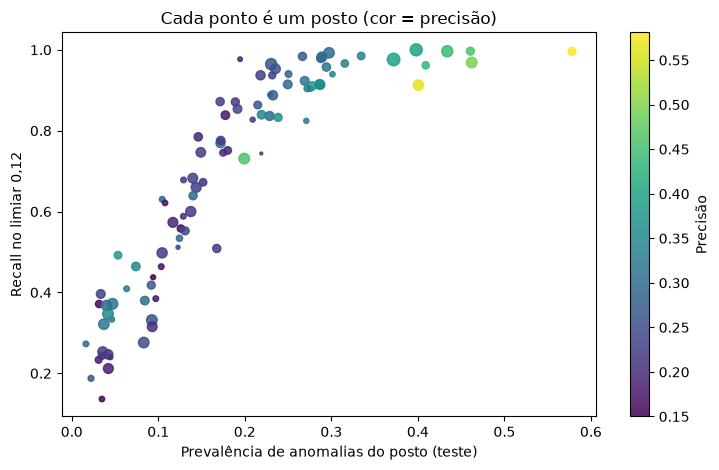

In [9]:
# Por posto individual (92 postos)
per_post = group_summary(test, "charging_post_id")
positives = test.groupby("charging_post_id")["y"].sum()
per_post.loc[positives[positives < 20].index, ["AP modelo", "AP baseline"]] = np.nan   # AP instável com poucas anomalias

print("Distribuição entre postos (teste final):")
display(per_post[["Sessões", "Prevalência", "AP modelo", "Precisão", "Recall", "Alertas/1000", "FN/1000"]].describe().round(3).loc[["min", "25%", "50%", "75%", "max"]])
print("Correlação de Spearman entre prevalência do posto no teste e: recall =",
      round(per_post["Prevalência"].corr(per_post["Recall"], method="spearman"), 3),
      "| precisão =", round(per_post["Prevalência"].corr(per_post["Precisão"], method="spearman"), 3))

print("Cinco postos com menor recall:")
display(per_post.sort_values("Recall").head(5)[["Sessões", "Prevalência", "AP modelo", "AP baseline", "Precisão", "Recall", "FN/1000"]].round(3))
print("Cinco postos com mais falsos alertas por 1000 sessões:")
display(per_post.sort_values("FP/1000", ascending=False).head(5)[["Sessões", "Prevalência", "Precisão", "Recall", "Alertas/1000", "FP/1000"]].round(3))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
sc = ax.scatter(per_post["Prevalência"], per_post["Recall"], s=per_post["Sessões"] / 40, c=per_post["Precisão"], cmap="viridis", alpha=0.85)
ax.set(xlabel="Prevalência de anomalias do posto (teste)", ylabel="Recall no limiar 0,12", title="Cada ponto é um posto (cor = precisão)")
plt.colorbar(sc, label="Precisão")
plt.tight_layout()
plt.show()

A variação entre postos é grande: recall de 0,14 a 1,00 (mediana 0,75) e alertas de 15 a 1 000 por 1000 sessões. O recall de cada posto é quase uma função da sua prevalência (Spearman 0,95), enquanto a precisão depende bem menos (0,54).

- Nos cinco postos com mais falsos alertas (80, 91, 88, 82, 87) alertam-se 88 % a 99 % das sessões e o recall é 0,94 a 0,99, mas a precisão é quase igual à prevalência: o alerta quase não distingue sessões.
- Nos cinco postos com menor recall (17, 18, 53, 38, 42; prevalência de 2 % a 5 %) perdem-se 76 % a 86 % das anomalias.

Na prática o modelo comporta-se como um detetor de "posto em mau estado". Um limiar único gera fadiga de alertas nos postos piores e deixa passar anomalias nos melhores; um limiar por grupo de risco, definido no desenvolvimento, é uma melhoria a testar.

## 5.5 Análise de erros

Com o limiar congelado há quatro tipos de sessão: alertas corretos (TP), falsos alertas (FP), anomalias perdidas (FN) e normais sem alerta (TN). Procuram-se padrões em **quem** são os FP e os FN: estado recente do posto, causa da falha, hora do dia, período tarifário, local e perfil do utilizador.

In [10]:
print("Contagens no teste:")
display(test["outcome"].value_counts().reindex(["TP", "FP", "FN", "TN"]).to_frame("Sessões").T)

profile_cols = [
    "post_previous_abnormal_rate_1d", "post_previous_abnormal_rate_7d", "post_previous_abnormal_rate_30d",
    "post_hours_since_previous_completed_abnormal", "post_previous_sessions_1d",
    "user_previous_abnormal_rate_30d", "user_previous_sessions_30d", "is_new_user", "hour",
]
profile = test.groupby("outcome")[profile_cols].mean().T[["TP", "FP", "FN", "TN"]]
print("Média das variáveis principais por tipo de resultado:")
display(profile.round(3))

# Estado recente do posto: taxa de anomalias do posto nas últimas 24 h.
bins = [-0.001, 0.10, 0.20, 0.35, 1.0]
labels = ["até 0,10", "(0,10; 0,20]", "(0,20; 0,35]", "> 0,35"]
test["rate_1d_bin"] = pd.cut(test["post_previous_abnormal_rate_1d"], bins=bins, labels=labels)

def error_rates(frame, by):
    rows = []
    n_fn_total = (frame["outcome"] == "FN").sum()
    n_fp_total = (frame["outcome"] == "FP").sum()
    for key, g in frame.groupby(by, observed=True):
        positives, negatives = (g["y"] == 1).sum(), (g["y"] == 0).sum()
        fn, fp = (g["outcome"] == "FN").sum(), (g["outcome"] == "FP").sum()
        rows.append({
            by: key, "Sessões": len(g), "Prevalência": g["y"].mean(),
            "Taxa de alerta": g["alert_model"].mean(),
            "Taxa de FN (entre anómalas)": fn / positives if positives else np.nan,
            "Taxa de FP (entre normais)": fp / negatives if negatives else np.nan,
            "% dos FN totais": fn / n_fn_total,
            "% dos FP totais": fp / n_fp_total,
        })
    return pd.DataFrame(rows).set_index(by)

by_rate = error_rates(test, "rate_1d_bin")
print("Erros por nível de taxa de anomalias do posto nas últimas 24 h:")
display(by_rate.round(3))

Contagens no teste:


outcome,TP,FP,FN,TN
Sessões,21297,45572,3974,60304


Média das variáveis principais por tipo de resultado:


outcome,TP,FP,FN,TN
post_previous_abnormal_rate_1d,0.378,0.232,0.122,0.111
post_previous_abnormal_rate_7d,0.354,0.246,0.113,0.092
post_previous_abnormal_rate_30d,0.323,0.257,0.126,0.099
post_hours_since_previous_completed_abnormal,7.909,14.046,38.502,47.728
post_previous_sessions_1d,16.564,13.223,11.894,12.219
user_previous_abnormal_rate_30d,0.285,0.235,0.154,0.138
user_previous_sessions_30d,36.927,44.920,48.418,62.751
is_new_user,0.147,0.210,0.075,0.061
hour,13.901,13.814,14.139,14.180


Erros por nível de taxa de anomalias do posto nas últimas 24 h:


,Sessões,Prevalência,Taxa de alerta,Taxa de FN (entre anómalas),Taxa de FP (entre normais),% dos FN totais,% dos FP totais
rate_1d_bin,,,,,,,
"até 0,10",42588,0.077,0.178,0.559,0.156,0.460,0.135
"(0,10; 0,20]",45529,0.141,0.475,0.267,0.433,0.433,0.371
"(0,20; 0,35]",26237,0.240,0.804,0.066,0.763,0.104,0.334
"> 0,35",16793,0.553,0.986,0.002,0.970,0.004,0.160


**Falsos negativos (FN, 3 974).** São sessões em postos aparentemente saudáveis. A taxa de anomalias do posto nas últimas 24 h é 0,122, quase igual à das sessões normais corretamente ignoradas (TN: 0,111) e muito inferior à dos TP (0,378). A última anomalia do posto foi há 38,5 h (TN: 47,7 h; TP: 7,9 h). Com taxa até 0,10, 56 % das anomalias são perdidas; 89 % de todos os FN ocorrem com taxa até 0,20. São falhas isoladas, sem sinal prévio nas variáveis disponíveis, e por isso difíceis para qualquer modelo baseado em histórico.

**Falsos positivos (FP, 45 572).** Vêm de postos em mau estado: taxa a 24 h de 0,232 (TN: 0,111). Em postos com taxa superior a 0,35, 97 % das sessões normais recebem alerta (16 % de todos os FP, com precisão 0,55). Os utilizadores novos são mais frequentes entre os alertas (TP 15 %, FP 21 %) do que entre os não alertas (FN 8 %, TN 6 %).

A hora do dia e o período tarifário quase não distinguem os erros (taxa de FN entre 0,12 e 0,19), em linha com a importância nula destes grupos (secção 5.6).

Recall por causa de falha (só sessões anómalas do teste):


,Sessões,Recall (HGB),Recall (baseline),Probabilidade média
Causa de falha,,,,
Other faults of the charging pile,6276,0.849,0.906,0.492
Vehicle communications failure,4438,0.831,0.800,0.406
DC Output Fault,3718,0.826,0.908,0.334
Faulty charging connection,2772,0.920,0.980,0.381
Vehicle charging faults,2465,0.928,0.915,0.405
BMS failure,2438,0.775,0.789,0.280
Failure of non-system control loop components and assemblies,1577,0.663,0.743,0.295
Power conversion unit failure,900,0.946,0.987,0.588
DC switching device failure,633,0.867,0.970,0.436


Erros por faixa horária:


,Sessões,Prevalência,Taxa de alerta,Taxa de FN (entre anómalas),Taxa de FP (entre normais),% dos FN totais,% dos FP totais
hour_band,,,,,,,
00-05 h,11758,0.215,0.577,0.117,0.494,0.075,0.100
06-11 h,28244,0.185,0.498,0.173,0.424,0.227,0.214
12-17 h,50836,0.195,0.516,0.156,0.437,0.390,0.392
18-23 h,40309,0.189,0.491,0.161,0.410,0.309,0.294


Erros por período tarifário:


,Sessões,Prevalência,Taxa de alerta,Taxa de FN (entre anómalas),Taxa de FP (entre normais),% dos FN totais,% dos FP totais
tariff_period,,,,,,,
off_peak_00_08,16187,0.203,0.550,0.137,0.470,0.114,0.133
off_peak_11_13,18481,0.203,0.556,0.142,0.479,0.134,0.155
off_peak_22_24,12528,0.213,0.532,0.148,0.446,0.100,0.096
peak_08_11,14735,0.176,0.469,0.189,0.396,0.124,0.105
peak_13_19,48601,0.191,0.502,0.159,0.422,0.372,0.364
peak_21_22,6677,0.187,0.492,0.162,0.413,0.051,0.049
sharp_19_21,13938,0.174,0.462,0.174,0.385,0.106,0.097


Erros por local:


,Sessões,Prevalência,Taxa de alerta,Taxa de FN (entre anómalas),Taxa de FP (entre normais),% dos FN totais,% dos FP totais
location,,,,,,,
Technology Park,2666,0.030,0.027,0.759,0.020,0.015,0.001
Bus Station,17973,0.080,0.106,0.551,0.076,0.200,0.028
Industrial Park,6378,0.065,0.113,0.524,0.087,0.055,0.011
Park B,15296,0.089,0.211,0.450,0.178,0.153,0.055
Government Agency,11340,0.117,0.234,0.418,0.187,0.140,0.041
Financial Industrial Park,4860,0.162,0.447,0.278,0.394,0.055,0.035
Park A,6919,0.239,0.638,0.165,0.576,0.069,0.067
Expressway Service District B,4853,0.224,0.707,0.126,0.659,0.034,0.054
Shopping Mall,15475,0.265,0.620,0.123,0.527,0.127,0.131


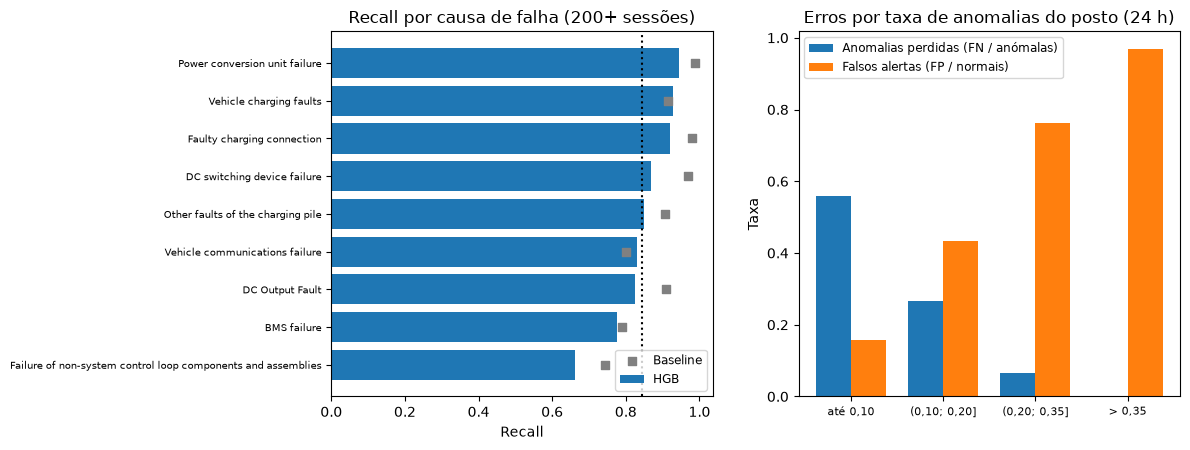

In [11]:
fault_rows = []
for cause, g in test[test["y"] == 1].groupby("end_cause"):
    fault_rows.append({
        "Causa de falha": cause, "Sessões": len(g),
        "Recall (HGB)": g["alert_model"].mean(),
        "Recall (baseline)": g["alert_base"].mean(),
        "Probabilidade média": g["prob"].mean(),
    })
by_cause = pd.DataFrame(fault_rows).sort_values("Sessões", ascending=False).set_index("Causa de falha")
print("Recall por causa de falha (só sessões anómalas do teste):")
display(by_cause.round(3))

test["hour_band"] = pd.cut(test["hour"], [-1, 5, 11, 17, 23], labels=["00-05 h", "06-11 h", "12-17 h", "18-23 h"])
print("Erros por faixa horária:")
display(error_rates(test, "hour_band").round(3))
print("Erros por período tarifário:")
display(error_rates(test, "tariff_period").round(3))
print("Erros por local:")
display(error_rates(test, "location").sort_values("Taxa de FN (entre anómalas)", ascending=False).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
top_causes = by_cause[by_cause["Sessões"] >= 200].sort_values("Recall (HGB)")
axes[0].barh(top_causes.index, top_causes["Recall (HGB)"], color="C0", label="HGB")
axes[0].scatter(top_causes["Recall (baseline)"], top_causes.index, color="grey", marker="s", zorder=3, label="Baseline")
axes[0].axvline(m_model["Recall"], ls=":", color="black")
axes[0].set(title="Recall por causa de falha (200+ sessões)", xlabel="Recall")
axes[0].legend(fontsize=8.5, loc="lower right")
axes[0].tick_params(axis="y", labelsize=7.5)
x_pos = np.arange(len(by_rate))
width = 0.38
axes[1].bar(x_pos - width / 2, by_rate["Taxa de FN (entre anómalas)"], width, label="Anomalias perdidas (FN / anómalas)")
axes[1].bar(x_pos + width / 2, by_rate["Taxa de FP (entre normais)"], width, label="Falsos alertas (FP / normais)")
axes[1].set(title="Erros por taxa de anomalias do posto (24 h)", xticks=x_pos, xticklabels=by_rate.index, ylabel="Taxa")
axes[1].legend(fontsize=8.5)
axes[1].tick_params(axis="x", labelsize=8)
plt.tight_layout(w_pad=2.5)
plt.show()

- **Causa da falha.** O recall varia entre 0,66 (*Failure of non-system control loop components and assemblies*, 1 577 sessões) e 0,95 (*Power conversion unit failure*, 900 sessões); *BMS failure* tem 0,78. As causas com menor recall têm também a menor probabilidade média prevista (0,28 a 0,30), o que sugere que são menos previsíveis a partir do estado recente do posto. Nenhuma causa frequente é ignorada.
- **Local.** Os erros acompanham a prevalência do local. *Technology Park*, *Bus Station* e *Industrial Park* (prevalência de 3 % a 8 %) perdem 52 % a 76 % das anomalias, e só a *Bus Station* concentra 20 % dos FN. *Expressway Service District C*, *Wholesale Market* e *Tourist Attraction* (26 % a 33 %) têm 69 % a 91 % de falsos alertas entre as sessões normais; só a *Expressway C* gera 24 % dos FP.
- **Estado recente do posto** (figura da direita): à medida que a taxa a 24 h sobe, os FN desaparecem e os FP tornam-se a regra. É o mesmo compromisso entre recall e precisão, agora visível por nível de risco.

## 5.6 Interpretação do modelo final

O modelo é um conjunto de árvores com boosting: não tem coeficientes e as relações são não lineares, por isso usam-se métodos *post hoc* e agnósticos ao modelo:

- **Importância por permutação** (individual e **por grupos de variáveis**, permutando todas as colunas do grupo em conjunto). A versão por grupo responde à limitação principal da individual: variáveis correlacionadas (por exemplo as taxas a 1, 7 e 30 dias) dividem a importância entre si e cada uma parece pouco relevante.
- **Dependência parcial** (*partial dependence*) das duas variáveis dominantes, para ver a forma da relação.

Ambas são calculadas na última janela de validação temporal com o modelo treinado nos dados anteriores a essa janela, tal como na Task 4: **não usam o teste final**.

PR-AUC de referência na última validação: 0.6721


,Nº de variáveis,Queda média da AP,Desvio-padrão
Grupo,,,
Histórico do posto,13,0.4123,0.0013
Histórico do utilizador,15,0.0736,0.0010
Local e posto,3,0.0044,0.0006
Hora e dia da semana,4,0.0003,0.0001
Tarifa e preço,2,0.0000,0.0000
Meteorologia,3,-0.0003,0.0001


,Variável,Queda média da AP,Desvio-padrão
10,post_previous_abnormal_rate_1d,0.2256,0.0005
19,post_hours_since_previous_completed_abnormal,0.0289,0.0004
13,post_previous_abnormal_rate_7d,0.0218,0.0011
33,user_days_since_previous_completed_abnormal,0.0133,0.0002
16,post_previous_abnormal_rate_30d,0.0118,0.0000
30,user_previous_abnormal_rate_730d,0.0068,0.0001
24,user_previous_abnormal_rate_30d,0.0065,0.0001
8,post_previous_sessions_1d,0.0036,0.0003
0,charging_post_id,0.0021,0.0003
17,post_hours_since_previous_completed_session,0.0020,0.0001


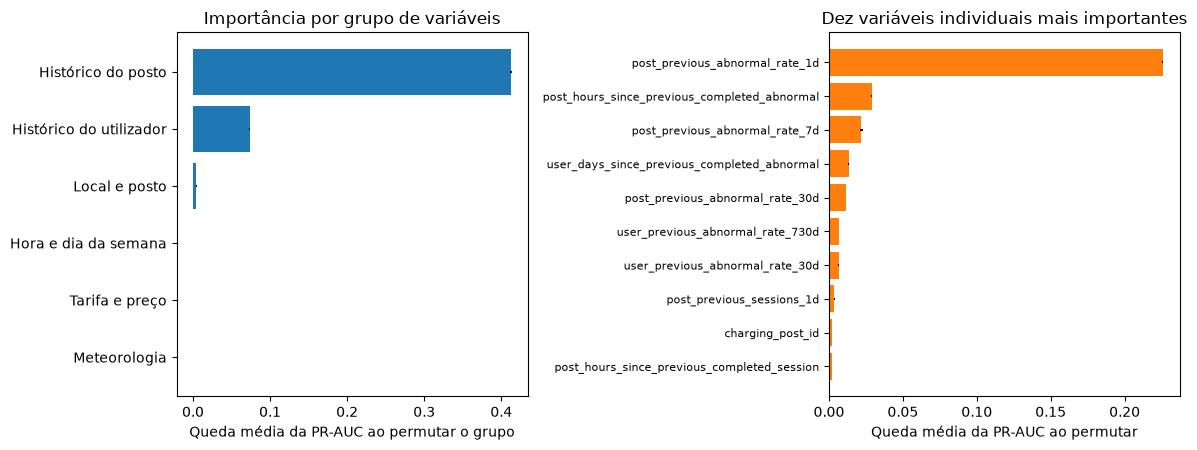

In [12]:
imp_train_idx, imp_val_idx = folds[-1]
imp_model = build_candidate(FROZEN["model"], FROZEN["params"])
imp_model.fit(X.iloc[imp_train_idx], y.iloc[imp_train_idx])
Xv, yv = X.iloc[imp_val_idx], y.iloc[imp_val_idx]
ap_ref = average_precision_score(yv, imp_model.predict_proba(Xv)[:, 1])

FEATURE_GROUPS = {
    "Histórico do posto": [c for c in X.columns if c.startswith("post_")],
    "Histórico do utilizador": [c for c in X.columns if c.startswith("user_") or c == "is_new_user"],
    "Hora e dia da semana": ["hour_sin", "hour_cos", "weekday_sin", "weekday_cos"],
    "Meteorologia": ["temperature", "relative_humidity", "precipitation_mm"],
    "Tarifa e preço": ["electricity_price", "tariff_period"],
    "Local e posto": ["charging_post_id", "location_information", "district_name"],
}
assert sorted(sum(FEATURE_GROUPS.values(), [])) == sorted(X.columns)

rng = np.random.default_rng(RANDOM_STATE)
group_rows = []
for name, cols in FEATURE_GROUPS.items():
    drops = []
    for _ in range(5):
        order = rng.permutation(len(Xv))
        Xp = Xv.copy()
        for col in cols:                      # a mesma permutação para todo o grupo preserva as correlações internas
            Xp[col] = Xv[col].to_numpy()[order]
        drops.append(ap_ref - average_precision_score(yv, imp_model.predict_proba(Xp)[:, 1]))
    group_rows.append({"Grupo": name, "Nº de variáveis": len(cols), "Queda média da AP": np.mean(drops), "Desvio-padrão": np.std(drops, ddof=1)})
group_importance = pd.DataFrame(group_rows).sort_values("Queda média da AP", ascending=False).set_index("Grupo")
print(f"PR-AUC de referência na última validação: {ap_ref:.4f}")
display(group_importance.round(4))

perm = permutation_importance(imp_model, Xv, yv, scoring="average_precision", n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
single_importance = pd.DataFrame({"Variável": X.columns, "Queda média da AP": perm.importances_mean, "Desvio-padrão": perm.importances_std}).sort_values("Queda média da AP", ascending=False)
display(single_importance.head(10).round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
g = group_importance.sort_values("Queda média da AP")
axes[0].barh(g.index, g["Queda média da AP"], xerr=g["Desvio-padrão"], color="C0")
axes[0].set(title="Importância por grupo de variáveis", xlabel="Queda média da PR-AUC ao permutar o grupo")
s = single_importance.head(10).sort_values("Queda média da AP")
axes[1].barh(s["Variável"], s["Queda média da AP"], xerr=s["Desvio-padrão"], color="C1")
axes[1].set(title="Dez variáveis individuais mais importantes", xlabel="Queda média da PR-AUC ao permutar")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

- **O histórico do posto domina.** Permutar as 13 variáveis em conjunto reduz a PR-AUC em 0,412 (de 0,672 para perto da prevalência de 0,194). A variável individual mais importante é a taxa de anomalias do posto nas últimas 24 h (0,226), seguida das horas desde a última anomalia (0,029) e da taxa a 7 dias (0,022).
- **Histórico do utilizador.** Como grupo pesa 0,074, bastante mais do que a soma das suas melhores variáveis individuais (cerca de 0,03): as 15 variáveis são redundantes entre si e a importância individual subestima o grupo. Em contrapartida, na ablação da Task 3 (retreinar sem o grupo) o ganho foi só de +0,02 a +0,03 de PR-AUC. A permutação obriga o modelo a avaliar combinações irrealistas e sobrestima a dependência; a conclusão prudente é que o histórico do utilizador contribui pouco.
- **Local e posto 0,004; hora e dia 0,0003; tarifa 0,000; meteorologia -0,0003** (ruído): em linha com a ablação.

**Limitações da interpretação.**

1. A importância por permutação descreve o modelo, não o fenómeno, e não é causal.
2. Foi calculada numa única janela de validação (a última) e não no teste final, para não o usar para decidir.
3. Variáveis correlacionadas repartem ou distorcem a importância; a permutação por grupos atenua o problema mas não o elimina.
4. Uma taxa de falhas recente alta pode refletir uma avaria que persiste ou apenas um registo de falhas mais atento; os dados não permitem separar as duas hipóteses.
5. Não explica decisões individuais.

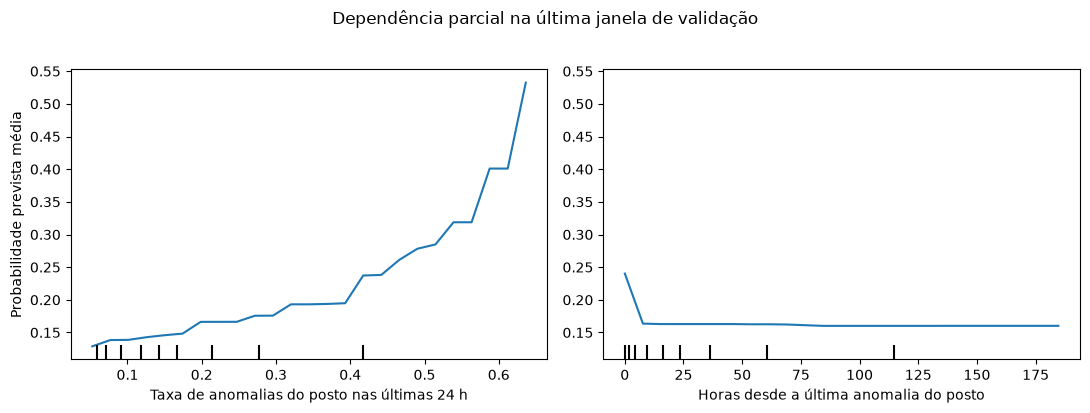

In [13]:
pdp_features = ["post_previous_abnormal_rate_1d", "post_hours_since_previous_completed_abnormal"]
pdp_sample = Xv.dropna(subset=pdp_features).sample(8000, random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
PartialDependenceDisplay.from_estimator(imp_model, pdp_sample, pdp_features, kind="average", grid_resolution=25, ax=axes)
axes[0].set(xlabel="Taxa de anomalias do posto nas últimas 24 h", ylabel="Probabilidade prevista média")
axes[1].set(xlabel="Horas desde a última anomalia do posto", ylabel="")
fig.suptitle("Dependência parcial na última janela de validação", y=1.02)
plt.tight_layout()
plt.show()

A probabilidade prevista cresce de forma monótona e acelerada com a taxa de anomalias das últimas 24 h, de cerca de 0,13 (taxa 0,05) a 0,53 (taxa 0,63). Em relação ao tempo desde a última anomalia só contam as primeiras horas: a probabilidade média é 0,24 logo após uma falha, desce para cerca de 0,16 em 8 a 10 horas e fica estável. O efeito é de curto prazo (persistência de falhas) e não linear, e é por isso que uma regressão logística sem transformações o capta pior. A PDP mostra apenas o efeito médio e esconde interações; foi calculada numa amostra de 8 000 sessões.

## 5.7 Consequências do limiar e utilidade operacional

O limiar de 0,12 foi escolhido para privilegiar o recall. A tabela traduz-o para a operação (por 1 000 sessões do teste). A segunda tabela mostra, para vários **orçamentos de alertas**, o que se consegue se a capacidade de resposta for limitada: alertam-se as sessões de maior risco até esgotar o orçamento. É uma vista descritiva que **não muda o limiar congelado**.

In [14]:
n_test = len(test)
tp_12, fp_12 = m_model["Alertas corretos / 1000 (TP)"], m_model["Falsos alertas / 1000 (FP)"]
m_050 = full_metrics(y_t, test["prob"], alert_050)
tp_50, fp_50 = m_050["Alertas corretos / 1000 (TP)"], m_050["Falsos alertas / 1000 (FP)"]
extra_fp_per_tp = (fp_12 - fp_50) / (tp_12 - tp_50)
print(f"Passar do limiar 0,50 para 0,12: +{tp_12 - tp_50:.1f} anomalias detetadas e +{fp_12 - fp_50:.1f} falsos alertas por 1000 sessões")
print(f"Custo marginal: {extra_fp_per_tp:.2f} falsos alertas por cada anomalia adicional detetada")
print(f"Compensa se perder uma anomalia custar mais de {extra_fp_per_tp:.1f} falsos alertas (razão de custos FN/FP > {extra_fp_per_tp:.1f})")

n_days = test["start"].dt.normalize().nunique()
n_posts = test["charging_post_id"].nunique()
sessions_pd = n_test / (n_posts * n_days)
print(f"Teste: {n_posts} postos, {n_days} dias -> {sessions_pd:.1f} sessões por posto e dia; "
      f"{sessions_pd * test['alert_model'].mean():.1f} alertas por posto e dia "
      f"({sessions_pd * tp_12 / 1000:.1f} corretos e {sessions_pd * fp_12 / 1000:.1f} falsos)")

def top_share(score, y_true, share):
    k = int(round(share * len(y_true)))
    order = np.argsort(-np.asarray(score), kind="stable")[:k]
    tp = np.asarray(y_true)[order].sum()
    return {"Precisão": tp / k, "Recall": tp / np.asarray(y_true).sum(), "Lift": (tp / k) / np.mean(y_true)}

budget_rows = []
for share in [0.05, 0.10, 0.20, 0.30, float(test["alert_model"].mean())]:
    mod, bas = top_share(test["prob"], y_t, share), top_share(test["base"], y_t, share)
    budget_rows.append({
        "Sessões alertadas": f"{share:.1%}",
        "Precisão HGB": mod["Precisão"], "Recall HGB": mod["Recall"], "Lift HGB": mod["Lift"],
        "Precisão baseline": bas["Precisão"], "Recall baseline": bas["Recall"], "Lift baseline": bas["Lift"],
    })
budget = pd.DataFrame(budget_rows).set_index("Sessões alertadas")
display(budget.round(3))

Passar do limiar 0,50 para 0,12: +95.5 anomalias detetadas e +321.1 falsos alertas por 1000 sessões
Custo marginal: 3.36 falsos alertas por cada anomalia adicional detetada
Compensa se perder uma anomalia custar mais de 3.4 falsos alertas (razão de custos FN/FP > 3.4)
Teste: 92 postos, 153 dias -> 9.3 sessões por posto e dia; 4.8 alertas por posto e dia (1.5 corretos e 3.2 falsos)


,Precisão HGB,Recall HGB,Lift HGB,Precisão baseline,Recall baseline,Lift baseline
Sessões alertadas,,,,,,
5.0%,0.846,0.219,4.388,0.522,0.135,2.710
10.0%,0.700,0.364,3.635,0.469,0.243,2.433
20.0%,0.528,0.549,2.743,0.406,0.422,2.109
30.0%,0.432,0.673,2.242,0.365,0.567,1.892
51.0%,0.318,0.843,1.653,0.293,0.776,1.522


- **O que o limiar 0,12 significa em operação:** 4,8 alertas por posto e dia (em 9,3 sessões), dos quais 1,5 corretos e 3,2 falsos. Cada alerta é verdadeiro em 32 % dos casos (1,65 vezes a prevalência).
- **Se a capacidade de resposta for limitada,** o modelo vale muito mais do que a baseline: alertando só 10 % das sessões, a precisão é 0,70 (3,6 vezes a prevalência) com 36 % de recall, contra 0,47 e 24 % da baseline; com 20 %, 0,53 e 55 % contra 0,41 e 42 %. A vantagem é maior quando o orçamento de alertas é pequeno.
- **Custo marginal.** Passar do limiar 0,50 para 0,12 deteta mais 95,5 anomalias à custa de mais 321,1 falsos alertas por 1000 sessões, ou seja, 3,4 falsos alertas por anomalia adicional. Só compensa se perder uma anomalia custar mais de 3,4 falsos alertas, razão que não foi medida e tem de ser validada com os custos reais.
- **Utilidade.** O modelo é útil como ferramenta de priorização barata (marcar sessões ou postos para monitorização automática, ordenar a fila de manutenção). Não é adequado se cada alerta exigir intervenção humana imediata: seriam 4,8 intervenções por posto e dia. Nesse caso convém usar um orçamento de alertas (5 % a 20 % das sessões) ou um limiar mais alto (0,50: 9 % de alertas, precisão 0,72, recall 0,35).

## 5.8 Conclusões, limitações e recomendações

**Conclusões**

1. O modelo final é o `HistGradientBoosting`, com PR-AUC 0,593 no teste (baseline 0,389; prevalência 0,193) e ROC-AUC 0,813. No limiar congelado (0,12) deteta 84,3 % das anomalias, com precisão 0,319, MCC 0,325 e balanced accuracy 0,706: por 1000 sessões, 162 alertas corretos, 347 falsos e 30 anomalias perdidas.
2. Supera a baseline em todos os meses, distritos e grupos de risco, e a igual taxa de alertas deteta mais anomalias (84,3 % contra 77,6 %).
3. O sinal vem quase todo do estado recente do posto (taxa de falhas nas últimas 24 h e horas desde a última falha). As falhas isoladas em postos saudáveis são quase invisíveis (56 % das anomalias com taxa recente até 0,10 são perdidas).
4. O desempenho é heterogéneo: recall 0,49 nos postos de risco baixo e 0,93 nos de risco alto; 32 % a 72 % de sessões alertadas conforme o distrito.
5. O limiar 0,12 é uma decisão de custos: cada anomalia adicional face ao limiar 0,50 custa 3,4 falsos alertas.

**Limitações**

- O teste cobre 5 meses e um único corte temporal, sem intervalos de confiança; sessões do mesmo posto não são independentes, pelo que diferenças pequenas (por exemplo HGB contra RF) não estão suportadas estatisticamente.
- Hiperparâmetros, limiar e seleção do modelo usaram os mesmos folds de desenvolvimento, com algum otimismo possível; uma validação aninhada seria mais rigorosa.
- A razão de custos entre falsos negativos e falsos positivos é assumida, não medida.
- A prevalência varia entre meses (0,165 a 0,229) e o limiar fixo gera mais falsos alertas quando desce.
- As análises por grupo, de erros e de interpretação são descritivas e não foram usadas para alterar o modelo.

**Recomendações**

1. Definir a ação associada ao alerta e medir os custos reais antes de fixar o limiar; considerar um orçamento de alertas (por exemplo, os 10 % a 20 % de sessões com maior probabilidade) em vez de um limiar fixo.
2. Testar limiares ou calibração por grupo de risco do posto, definidos no desenvolvimento, para reduzir a fadiga de alertas nos postos piores e as perdas nos melhores, com validação temporal.
3. Monitorizar mensalmente a prevalência, o recall e a precisão, e retreinar ou recalibrar quando derivarem (o treino demora segundos).
4. Para as falhas isoladas, procurar variáveis novas fora do histórico de sessões (por exemplo, telemetria do equipamento, idade e manutenção do posto); trata-se de hipóteses a testar, não de resultados deste trabalho.
5. Reforçar a avaliação com validação temporal aninhada, intervalos de confiança por blocos de dias e calibração das probabilidades.